In [ ]:
!pip install mne -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 86.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from mne.io import read_raw_edf, concatenate_raws
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras.layers import (Input, Conv2D, DepthwiseConv2D, SeparableConv2D,
                                      BatchNormalization, Activation, AveragePooling2D,
                                      Dropout, Flatten, Dense)
from tensorflow.keras.models import Model
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
mne.set_log_level('WARNING')
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMAGERY_RUNS = [4, 8, 12]
TMIN, TMAX = 0.0, 4.0
def load_subject(subject_id, data_path=None):
    raw_fnames = eegbci.load_data(subject_id, IMAGERY_RUNS, path=data_path, update_path=True)
    raws = [read_raw_edf(f, preload=True) for f in raw_fnames]
    raw = concatenate_raws(raws)
    eegbci.standardize(raw)
    montage = mne.channels.make_standard_montage('standard_1005')
    raw.set_montage(montage, on_missing='ignore')
    raw.filter(8.0, 30.0, fir_design='firwin', skip_by_annotation='edge')
    events, event_id = mne.events_from_annotations(raw)
    picks = mne.pick_types(raw.info, eeg=True, exclude='bads')
    epochs = mne.Epochs(raw, events, event_id={'left': event_id['T1'], 'right': event_id['T2']},
                         tmin=TMIN, tmax=TMAX, proj=True, picks=picks,
                         baseline=None, preload=True)
    X = epochs.get_data()
    y = (epochs.events[:, -1] == event_id['T2']).astype(int)
    return X, y

In [ ]:
BAD_SUBJECTS = {88, 89, 92, 100, 104}
SUBJECTS = [s for s in range(1, 71) if s not in BAD_SUBJECTS]
X_list, y_list, group_list = [], [], []
for subj in SUBJECTS:
    try:
        X, y = load_subject(subj)
        X_list.append(X)
        y_list.append(y)
        group_list.append(np.full(len(y), subj))
        print(f"Subject {subj:3d}: {len(y)} trials loaded")
    except Exception as e:
        print(f"Subject {subj:3d}: skipped ({e})")
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)
groups = np.concatenate(group_list, axis=0)
print("\nFinal dataset:", X.shape, "| labels:", np.bincount(y))

Subject   1: 45 trials loaded


Subject   2: 45 trials loaded


Subject   3: 45 trials loaded


Subject   4: 45 trials loaded


Subject   5: 45 trials loaded


Subject   6: 45 trials loaded


... (60 outputs left out)

Subject  67: 45 trials loaded


Subject  68: 45 trials loaded


Subject  69: 45 trials loaded


Subject  70: 45 trials loaded

Final dataset: (3144, 64, 641) | labels: [1591 1553]


In [ ]:
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
trainval_idx, test_idx = next(gss_test.split(X, y, groups))
X_trainval, y_trainval, groups_trainval = X[trainval_idx], y[trainval_idx], groups[trainval_idx]
X_test, y_test = X[test_idx], y[test_idx]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(gss_val.split(X_trainval, y_trainval, groups_trainval))
X_train, y_train = X_trainval[train_idx], y_trainval[train_idx]
X_val, y_val = X_trainval[val_idx], y_trainval[val_idx]
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Subjects — train:", len(set(groups_trainval[train_idx])),
      "val:", len(set(groups_trainval[val_idx])),
      "test:", len(set(groups[test_idx])))

Train: (2114, 64, 641) | Val: (402, 64, 641) | Test: (628, 64, 641)
Subjects — train: 47 val: 9 test: 14


In [ ]:
def normalize_per_subject(X, groups):
    X_norm = np.empty_like(X)
    for subj in np.unique(groups):
        mask = groups == subj
        mean = X[mask].mean(axis=(0, 2), keepdims=True)
        std = X[mask].std(axis=(0, 2), keepdims=True) + 1e-8
        X_norm[mask] = (X[mask] - mean) / std
    return X_norm
X_train_n = normalize_per_subject(X_train, groups_trainval[train_idx])[..., np.newaxis]
X_val_n = normalize_per_subject(X_val, groups_trainval[val_idx])[..., np.newaxis]
X_test_n = normalize_per_subject(X_test, groups[test_idx])[..., np.newaxis]
Chans, Samples = X_train.shape[1], X_train.shape[2]
print("Chans:", Chans, "| Samples per trial:", Samples)

Chans: 64 | Samples per trial: 641


In [ ]:
def augment(X, y, n_augments=2, noise_std=0.05, max_shift=10):
    X_aug, y_aug = [X], [y]
    for _ in range(n_augments):
        shifted = np.roll(X, shift=np.random.randint(-max_shift, max_shift), axis=2)
        noisy = shifted + np.random.normal(0, noise_std, shifted.shape).astype(np.float32)
        X_aug.append(noisy)
        y_aug.append(y)
    return np.concatenate(X_aug, axis=0), np.concatenate(y_aug, axis=0)
X_train_aug, y_train_aug = augment(X_train_n, y_train, n_augments=2)
print("Train set after augmentation:", X_train_aug.shape)

Train set after augmentation: (6342, 64, 641, 1)


In [ ]:
def build_eegnet(nb_classes, Chans, Samples, dropoutRate=0.5, kernLength=64, F1=8, D=2, F2=16):
    inputs = Input(shape=(Chans, Samples, 1))
    x = Conv2D(F1, (1, kernLength), padding='same', use_bias=False)(inputs)
    x = BatchNormalization()(x)
    x = DepthwiseConv2D((Chans, 1), use_bias=False, depth_multiplier=D,
                         depthwise_constraint=max_norm(1.))(x)
    x = BatchNormalization()(x)
    x = Activation('elu')(x)
    x = AveragePooling2D((1, 4))(x)
    x = Dropout(dropoutRate)(x)
    x = SeparableConv2D(F2, (1, 16), padding='same', use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation('elu')(x)
    x = AveragePooling2D((1, 8))(x)
    x = Dropout(dropoutRate)(x)
    x = Flatten()(x)
    x = Dense(nb_classes, kernel_constraint=max_norm(0.25))(x)
    outputs = Activation('softmax')(x)
    return Model(inputs=inputs, outputs=outputs)
model = build_eegnet(nb_classes=2, Chans=Chans, Samples=Samples, kernLength=80, F1=16, D=2, F2=32, dropoutRate=0.5)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 641, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 641, 16)    │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 641, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 1, 641, 32)     │         2,048 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 641, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 641, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 160, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 160, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 1, 160, 32)     │         1,536 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1, 160, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1, 160, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 20, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 20, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         1,282 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,466 (25.26 KB)

 Trainable params: 6,306 (24.63 KB)

 Non-trainable params: 160 (640.00 B)

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)
]
history = model.fit(
    X_train_aug, y_train_aug,
    validation_data=(X_val_n, y_val),
    epochs=150,
    batch_size=64,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/150
100/100 - 26s - 256ms/step - accuracy: 0.5194 - loss: 0.6932 - val_accuracy: 0.5075 - val_loss: 0.6926 - learning_rate: 0.0010
Epoch 2/150
100/100 - 5s - 51ms/step - accuracy: 0.5971 - loss: 0.6623 - val_accuracy: 0.6517 - val_loss: 0.6662 - learning_rate: 0.0010
Epoch 3/150
100/100 - 5s - 53ms/step - accuracy: 0.6638 - loss: 0.6049 - val_accuracy: 0.6692 - val_loss: 0.6150 - learning_rate: 0.0010
Epoch 4/150
100/100 - 5s - 51ms/step - accuracy: 0.6928 - loss: 0.5686 - val_accuracy: 0.6940 - val_loss: 0.5842 - learning_rate: 0.0010
Epoch 5/150
100/100 - 5s - 52ms/step - accuracy: 0.7211 - loss: 0.5411 - val_accuracy: 0.7239 - val_loss: 0.5525 - learning_rate: 0.0010
Epoch 6/150
100/100 - 10s - 103ms/step - accuracy: 0.7312 - loss: 0.5195 - val_accuracy: 0.6343 - val_loss: 0.5964 - learning_rate: 0.0010
Epoch 7/150
100/100 - 5s - 53ms/step - accuracy: 0.7532 - loss: 0.4983 - val_accuracy: 0.6816 - val_loss: 0.5813 - learning_rate: 0.0010
Epoch 8/150
100/100 - 5s - 52ms/step 

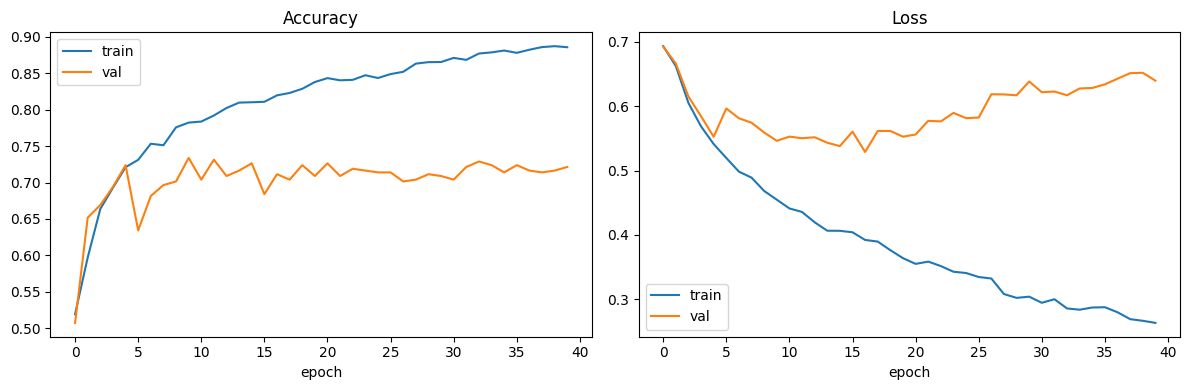

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='val')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='val')
axes[1].set_title('Loss'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

Test accuracy: 75.16%
Chance level:  50.00%

              precision    recall  f1-score   support

        left       0.73      0.81      0.77       316
       right       0.78      0.69      0.73       312

    accuracy                           0.75       628
   macro avg       0.75      0.75      0.75       628
weighted avg       0.75      0.75      0.75       628



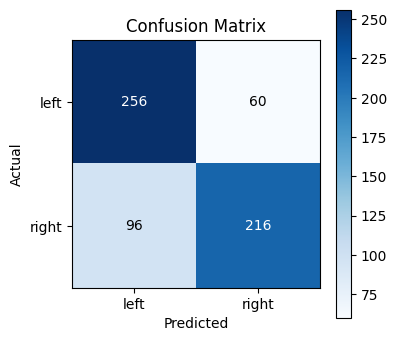

In [ ]:
test_loss, test_acc = model.evaluate(X_test_n, y_test, verbose=0)
y_pred = np.argmax(model.predict(X_test_n, verbose=0), axis=1)
print(f"Test accuracy: {test_acc*100:.2f}%")
print(f"Chance level:  50.00%\n")
print(classification_report(y_test, y_pred, target_names=['left', 'right']))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xticks([0, 1], ['left', 'right']); plt.yticks([0, 1], ['left', 'right'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                  color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.colorbar()
plt.show()